# EDA inicial — ZonaProp · Distrito Centro v2

Exploración reproducible de la versión enriquecida con barrios oficiales. Este notebook **no imputa**, **no elimina outliers** y **no modifica el dataset**. Los recortes visuales sólo afectan los límites de los gráficos.

In [11]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
PALETTE = sns.color_palette('colorblind')
plt.rcParams.update({'figure.figsize': (11, 6), 'axes.titleweight': 'bold', 'axes.labelsize': 11})

## 1. Carga y controles de integridad

In [12]:
def find_repo_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate / 'data').exists() and (candidate / 'src').exists():
            return candidate
    raise FileNotFoundError('No se encontró la raíz del repositorio')

ROOT = find_repo_root()
DATA_PATH = ROOT / 'data/processed/zonaprop_v2_eda_centro_v2_barrios.csv.gz'
df = pd.read_csv(DATA_PATH, low_memory=False)

assert len(df) == 9_582
assert df['property_id'].is_unique
assert df.shape[1] == 87

print(f'Archivo: {DATA_PATH.relative_to(ROOT)}')
print(f'Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'IDs únicos: {df.property_id.nunique():,}')

Archivo: data/processed/zonaprop_v2_eda_centro_v2_barrios.csv.gz
Dimensiones: 9,582 filas × 87 columnas
IDs únicos: 9,582


## 2. Calidad y completitud

`barrio` se conserva por trazabilidad, pero se excluye del análisis porque tiene 100% de faltantes. Para el análisis territorial se utiliza `barrio_oficial_geo`.

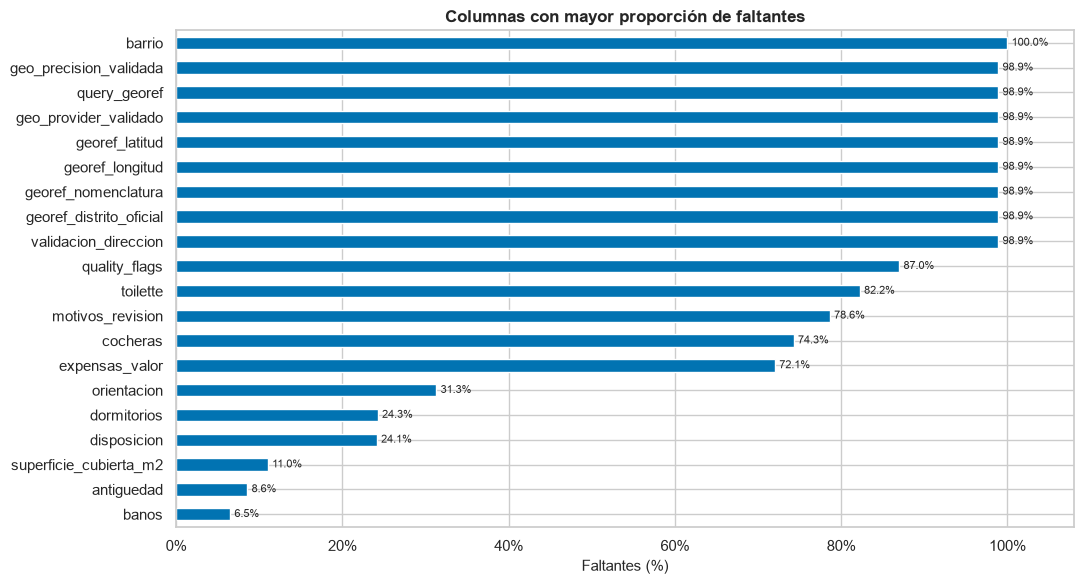

,n
Universo completo,9582
Barrio apto para EDA,8766
Barrio provisional,816
Requiere revisión,2046


In [13]:
missing = (df.isna().mean().mul(100).sort_values(ascending=False).head(20).sort_values())
ax = missing.plot.barh(color=PALETTE[0])
ax.set(title='Columnas con mayor proporción de faltantes', xlabel='Faltantes (%)', ylabel='')
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=8)
plt.xlim(0, 108)
plt.tight_layout()
plt.show()

quality = pd.Series({
    'Universo completo': len(df),
    'Barrio apto para EDA': int(df.barrio_geo_apto_eda_preliminar.sum()),
    'Barrio provisional': int((df.barrio_geo_estado == 'asignado_coordenada_pendiente').sum()),
    'Requiere revisión': int(df.requiere_revision.sum()),
}, name='n')
display(quality.to_frame())

## 3. Target: precio publicado y precio observado por m²

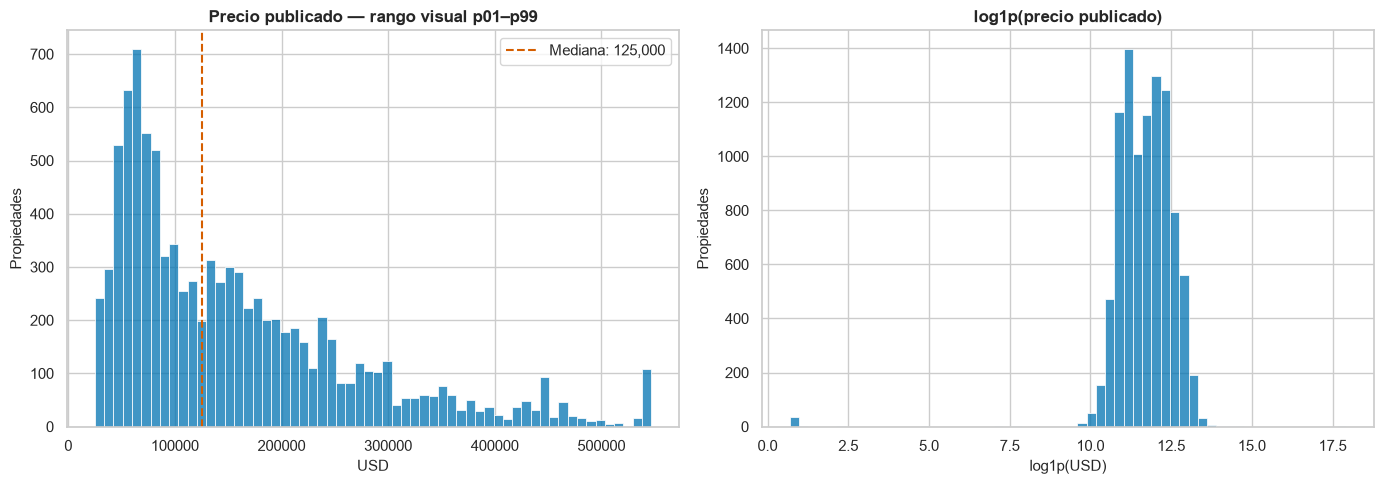

,precio
count,9.582000e+03
mean,1.647711e+05
std,6.303107e+05
min,1.000000e+00
1%,2.500000e+04
5%,4.129810e+04
25%,6.800000e+04
50%,1.250000e+05
75%,2.124700e+05
95%,4.100000e+05


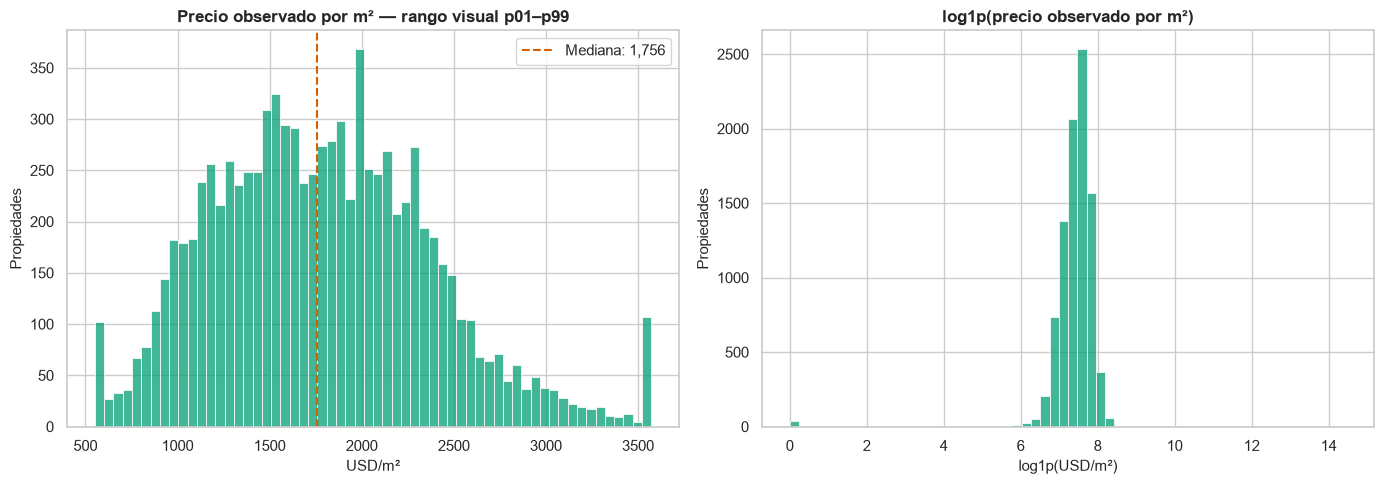

,precio_m2
count,9.062000e+03
mean,2.079706e+03
std,2.037470e+04
min,3.846154e-03
1%,5.513657e+02
5%,9.027778e+02
25%,1.336000e+03
50%,1.755933e+03
75%,2.176271e+03
95%,2.833211e+03


In [14]:
def distribution_pair(series, label, unit, color):
    values = pd.to_numeric(series, errors='coerce').dropna()
    p01, p99 = values.quantile([0.01, 0.99])
    visual = values.clip(p01, p99)  # sólo para visualización
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.histplot(visual, bins=60, ax=axes[0], color=color)
    axes[0].axvline(values.median(), color=PALETTE[3], linestyle='--', label=f'Mediana: {values.median():,.0f}')
    axes[0].set(title=f'{label} — rango visual p01–p99', xlabel=unit, ylabel='Propiedades')
    axes[0].legend()
    sns.histplot(np.log1p(values), bins=60, ax=axes[1], color=color)
    axes[1].set(title=f'log1p({label.lower()})', xlabel=f'log1p({unit})', ylabel='Propiedades')
    fig.tight_layout()
    plt.show()
    return values.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])

display(distribution_pair(df.precio_ultimo, 'Precio publicado', 'USD', PALETTE[0]).to_frame('precio'))
display(distribution_pair(df.precio_m2_observado, 'Precio observado por m²', 'USD/m²', PALETTE[2]).to_frame('precio_m2'))

## 4. Superficies y variables discretas

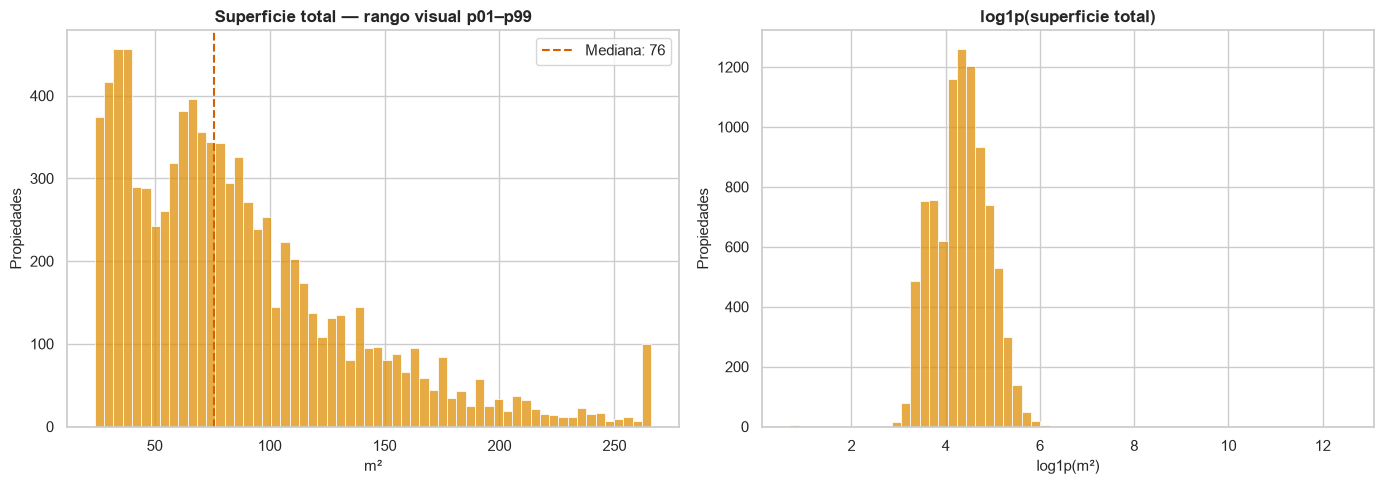

,superficie_total
count,9062.000000
mean,119.009159
std,2813.611274
min,1.000000
1%,24.000000
5%,30.000000
25%,48.000000
50%,76.000000
75%,111.000000
95%,190.000000


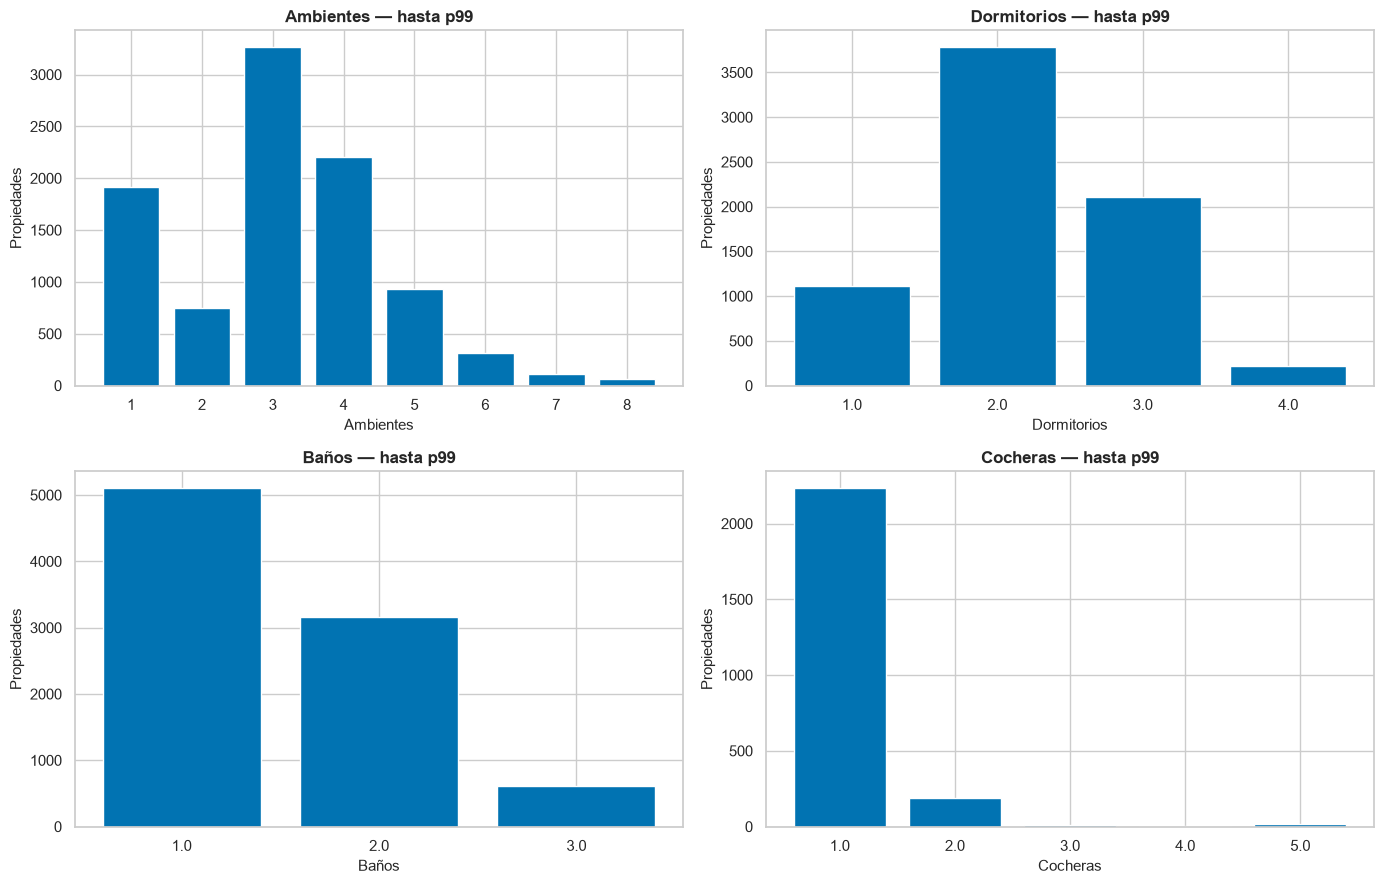

In [15]:
display(distribution_pair(df.superficie_total_m2, 'Superficie total', 'm²', PALETTE[1]).to_frame('superficie_total'))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, column, title in zip(axes.flat, ['ambientes', 'dormitorios', 'banos', 'cocheras'], ['Ambientes', 'Dormitorios', 'Baños', 'Cocheras']):
    values = pd.to_numeric(df[column], errors='coerce')
    upper = values.quantile(.99)
    counts = values[values <= upper].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=PALETTE[0])
    ax.set(title=f'{title} — hasta p99', xlabel=title, ylabel='Propiedades')
fig.tight_layout()
plt.show()

## 5. Distribución territorial

Sólo se incluyen filas con `barrio_geo_apto_eda_preliminar=True`. Los barrios con muestras pequeñas se muestran, pero no deben interpretarse como rankings estables.

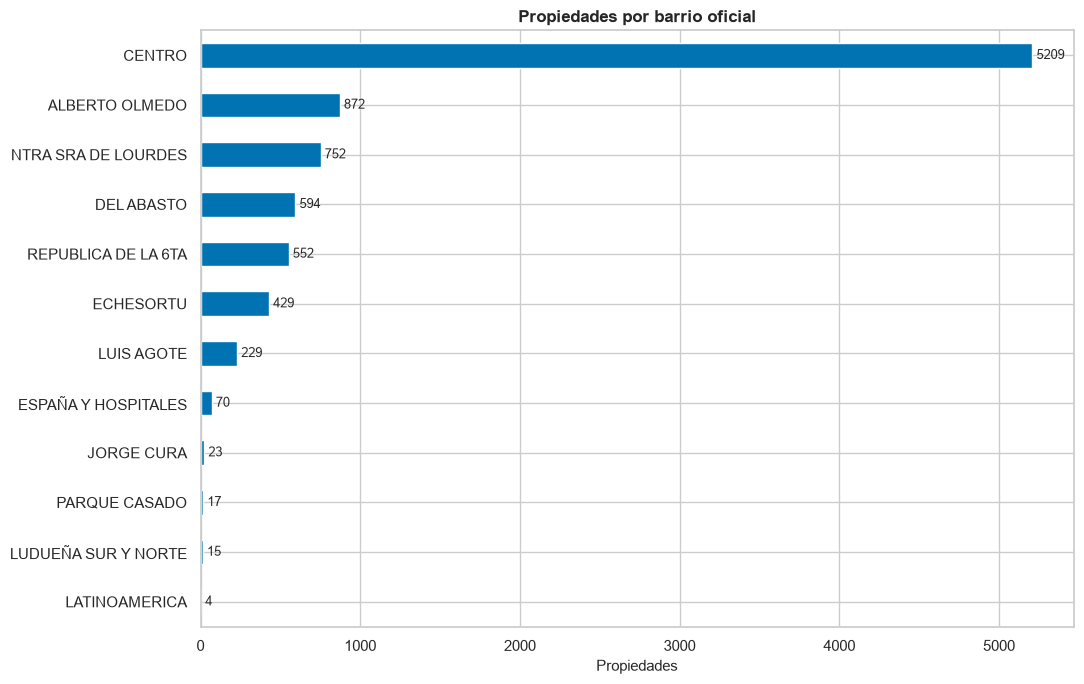

,n,precio_mediano,precio_m2_mediano
barrio_oficial_geo,,,
ALBERTO OLMEDO,872,"USD 145,000","USD 1,946"
NTRA SRA DE LOURDES,752,"USD 115,000","USD 1,877"
JORGE CURA,23,"USD 162,000","USD 1,825"
CENTRO,5209,"USD 135,000","USD 1,786"
DEL ABASTO,594,"USD 126,464","USD 1,774"
REPUBLICA DE LA 6TA,552,"USD 65,000","USD 1,444"
ECHESORTU,429,"USD 65,000","USD 1,429"
LUIS AGOTE,229,"USD 55,000","USD 1,423"
PARQUE CASADO,17,"USD 58,000","USD 1,250"


In [16]:
geo = df.loc[df.barrio_geo_apto_eda_preliminar].copy()
counts = geo.barrio_oficial_geo.value_counts().sort_values()
ax = counts.plot.barh(color=PALETTE[0], figsize=(11, 7))
ax.set(title='Propiedades por barrio oficial', xlabel='Propiedades', ylabel='')
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
plt.tight_layout()
plt.show()

barrio_stats = (geo.groupby('barrio_oficial_geo')
    .agg(n=('property_id', 'size'), precio_mediano=('precio_ultimo', 'median'), precio_m2_mediano=('precio_m2_observado', 'median'))
    .sort_values('precio_m2_mediano', ascending=False))
display(barrio_stats.style.format({'precio_mediano': 'USD {:,.0f}', 'precio_m2_mediano': 'USD {:,.0f}'}))

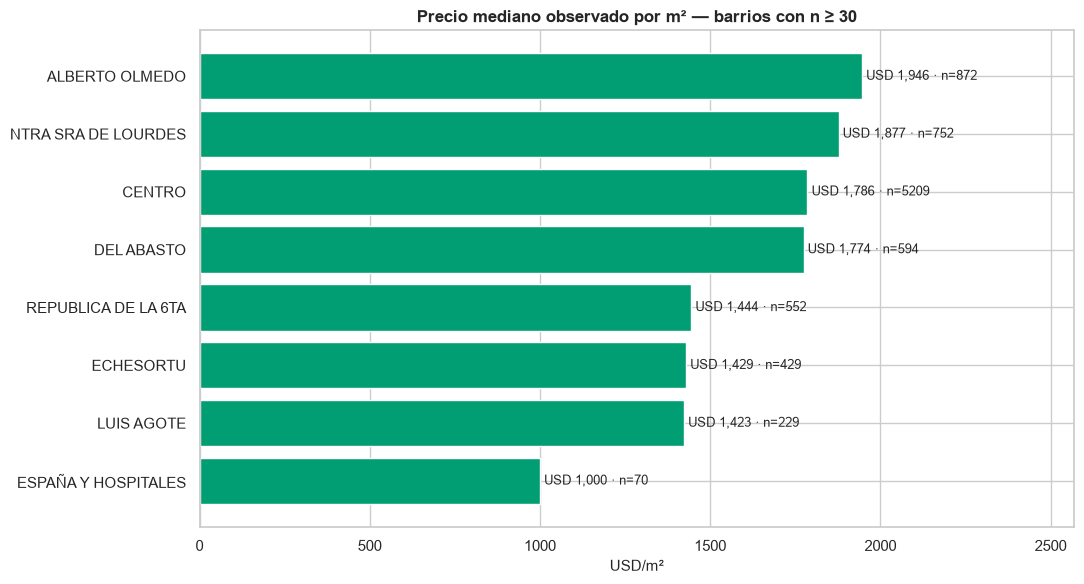

In [17]:
stable = barrio_stats.query('n >= 30').sort_values('precio_m2_mediano')
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(stable.index, stable.precio_m2_mediano, color=PALETTE[2])
ax.set(title='Precio mediano observado por m² — barrios con n ≥ 30', xlabel='USD/m²', ylabel='')
ax.bar_label(bars, labels=[f'USD {v:,.0f} · n={n}' for v, n in zip(stable.precio_m2_mediano, stable.n)], padding=3, fontsize=9)
ax.set_xlim(0, stable.precio_m2_mediano.max() * 1.32)
plt.tight_layout()
plt.show()

## 6. Cobertura espacial preliminar

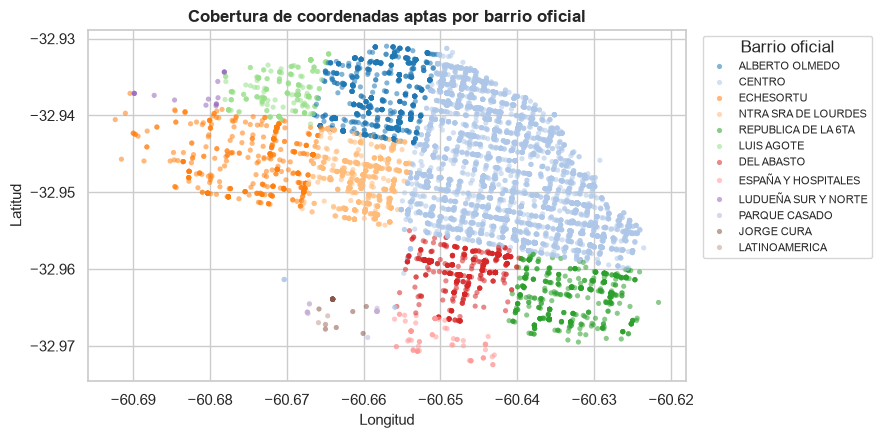

In [18]:
fig, ax = plt.subplots(figsize=(9, 9))
sns.scatterplot(data=geo, x='longitud', y='latitud', hue='barrio_oficial_geo', s=14, alpha=.55, linewidth=0, palette='tab20', ax=ax)
ax.set(title='Cobertura de coordenadas aptas por barrio oficial', xlabel='Longitud', ylabel='Latitud', aspect='equal')
ax.legend(title='Barrio oficial', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

## 7. Denominaciones comerciales: Pichincha y Abasto

In [19]:
text = (df.titulo.fillna('') + ' ' + df.descripcion_completa.fillna('') + ' ' + df.direccion_exacta.fillna(''))
mentions = pd.DataFrame({
    'Pichincha': text.str.contains(r'\bpichincha\b', case=False, regex=True),
    'Abasto': text.str.contains(r'\babasto\b', case=False, regex=True),
})
for label in mentions:
    table = df.loc[mentions[label]].groupby('barrio_oficial_geo').size().sort_values(ascending=False).rename('n')
    print(f'\nMenciones de {label}: {mentions[label].sum():,}')
    display(table.to_frame())


Menciones de Pichincha: 790


,n
barrio_oficial_geo,
ALBERTO OLMEDO,473
CENTRO,228
NTRA SRA DE LOURDES,46
LUIS AGOTE,23
JORGE CURA,11
ECHESORTU,6
PARQUE CASADO,3



Menciones de Abasto: 450


,n
barrio_oficial_geo,
DEL ABASTO,345
REPUBLICA DE LA 6TA,72
CENTRO,25
ESPAÑA Y HOSPITALES,4
NTRA SRA DE LOURDES,4


## 8. Casos problemáticos para auditoría

In [20]:
audit = pd.DataFrame(index=df.index)
audit['cubierta_mayor_total'] = df.superficie_cubierta_m2 > df.superficie_total_m2
audit['precio_extremo_p01_p99'] = ~df.precio_ultimo.between(df.precio_ultimo.quantile(.01), df.precio_ultimo.quantile(.99))
audit['superficie_faltante'] = df.superficie_total_m2.isna()
audit['superficie_extrema_p01_p99'] = df.superficie_total_m2.notna() & ~df.superficie_total_m2.between(df.superficie_total_m2.quantile(.01), df.superficie_total_m2.quantile(.99))
audit['cochera_posiblemente_no_incluida'] = text.str.contains(r'cochera.{0,45}(?:no (?:est[aá] )?incluida|aparte|adicional)', case=False, regex=True)
audit['coordenada_pendiente'] = ~df.apto_eda_espacial_preliminar

summary = audit.sum().sort_values(ascending=False).rename('n').to_frame()
summary['pct'] = summary.n / len(df) * 100
display(summary.style.format({'pct': '{:.2f}%'}))

problematic = df.loc[audit.any(axis=1), ['property_id', 'direccion_exacta', 'precio_ultimo', 'superficie_total_m2', 'superficie_cubierta_m2', 'barrio_oficial_geo', 'barrio_geo_estado']].copy()
problematic = problematic.join(audit.loc[problematic.index])
display(problematic.head(25))

,n,pct
coordenada_pendiente,816,8.52%
superficie_faltante,520,5.43%
cochera_posiblemente_no_incluida,408,4.26%
precio_extremo_p01_p99,176,1.84%
superficie_extrema_p01_p99,157,1.64%
cubierta_mayor_total,12,0.13%


,property_id,direccion_exacta,precio_ultimo,superficie_total_m2,superficie_cubierta_m2,barrio_oficial_geo,barrio_geo_estado,cubierta_mayor_total,precio_extremo_p01_p99,superficie_faltante,superficie_extrema_p01_p99,cochera_posiblemente_no_incluida,coordenada_pendiente
0,prop_6ad1ca5d1353b7a7,Santa Fe al 3000,73945.0,45.0,40.0,ALBERTO OLMEDO,asignado_coordenada_apta,False,False,False,False,True,False
3,prop_6a7b77f32fdd3294,Av. Francia 1485,74448.0,NaN,NaN,NTRA SRA DE LOURDES,asignado_coordenada_apta,False,False,True,False,False,False
6,prop_fadaa8daa45bd392,Pellegrini 3800,44000.0,NaN,NaN,ECHESORTU,asignado_coordenada_apta,False,False,True,False,False,False
9,prop_47cc846eb4e5183d,San Juan 1486 - Los Cipreses,49500.0,NaN,NaN,CENTRO,asignado_coordenada_apta,False,False,True,False,False,False
11,prop_c6fd1989625d766e,Alvear 1400,80833.0,NaN,NaN,NTRA SRA DE LOURDES,asignado_coordenada_apta,False,False,True,False,False,False
13,prop_8190d03d336420a8,Montevideo 1700,85000.0,NaN,NaN,CENTRO,asignado_coordenada_apta,False,False,True,False,False,False
14,prop_89f3f8d5fc234d66,1 de Mayo al 1100,49000.0,26.0,26.0,CENTRO,asignado_coordenada_pendiente,False,False,False,False,False,True
18,prop_f752b0302284bc78,1 de Mayo 1400- Monoambiente,76000.0,38.0,NaN,CENTRO,asignado_coordenada_pendiente,False,False,False,False,False,True
19,prop_cd6aa4210ebaa79f,Dorrego al 1600,39500.0,23.0,19.0,CENTRO,asignado_coordenada_apta,False,False,False,True,False,False
25,prop_1df528a768ee79ae,Av. Francia 817,54787.0,NaN,NaN,NTRA SRA DE LOURDES,asignado_coordenada_apta,False,False,True,False,False,False


## Lectura provisional

1. Las distribuciones deben interpretarse con estadísticas robustas y escala logarítmica, sin eliminar extremos antes de auditarlos.
2. La cobertura territorial está fuertemente concentrada en el barrio oficial CENTRO.
3. Los barrios con pocos casos requieren cautela y no deberían alimentar rankings simples.
4. Pichincha y Abasto funcionan también como denominaciones comerciales; sus menciones no sustituyen la asignación espacial oficial.
5. Las alertas generadas son una cola de revisión, no decisiones automáticas de preprocesamiento.